## Aprendizaje no Supervisado

Cruz, Pablo Danilo

Ricalde, Maximiliano Jeremias

Licenciatura en Análisis de Sistemas - Facultad de ciencias Exactas - UNSa -2026


## 0. Carga del DataSet y Librerias Necesarias

In [1]:
# --- Preparar el entorno: solo actúa si estás en Google Colab ---
import sys
import pandas as pd
from pathlib import Path

from src2.data import eliminar_columnas, imputar_media


import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from src2.features import rango_escenarios
from src2.split import aplanar_escenarios, separar_variables
from src2.unsupervised import (Detector, control_posicion, entrenar_fold, loso,
                               metricas, residualizar_tiempo)
RUTA = Path.cwd()
if not (RUTA / "datasets").exists():
    RUTA = RUTA.parent
sys.path.insert(0, str(RUTA / "Colab"))
BASE = RUTA / "datasets"


print("raíz:", RUTA)
print("leyendo CSVs...")
dfs = {
    "S0":     pd.read_csv(BASE / "datasetS0.csv"),
    "S1":     pd.read_csv(BASE / "datasetS1.csv"),
    "S1-alt": pd.read_csv(BASE / "datasetS1alt.csv"),
    "S2":     pd.read_csv(BASE / "datasetS2.csv"),
    "S3":     pd.read_csv(BASE / "datasetS3.csv"),
    "S4":     pd.read_csv(BASE / "datasetS4.csv"),
    "S5":     pd.read_csv(BASE / "datasetS5.csv"),
    "S6":     pd.read_csv(BASE / "datasetS6.csv"),
}

# Agregar el escenario a cada bloque antes de concatenar evita el
# DataFrame fragmentado que generaba el MultiIndex + reset_index.
df = (pd.concat(dfs, names=["escenario"])
      .reset_index(level="escenario")
      .reset_index(drop=True))
df = imputar_media(eliminar_columnas(df))
SEED = 42

raíz: /media/windows/Users/pablo/Documents/UNSA/4to/MetodosCuantitativos/TPFinal/tpfinal-colab
leyendo CSVs...


/tmp/ipykernel_311555/2430139625.py:45: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .reset_index(level="escenario")


## 1. Eliminacion de Columnas y Separacion de Variables

In [2]:
# --- Cargar los ocho escenarios y separar X de la etiqueta ---
brutos = dfs
dfs = {k: eliminar_columnas(bloque) for k, bloque in brutos.items()}
X, Y = {}, {}
for k, bloque in dfs.items():
    X[k], Y[k] = separar_variables(bloque)

print("escenarios:", list(dfs))
print("features por escenario:", {k: v.shape[1] for k, v in X.items()})
print("filas por escenario:", {k: len(v) for k, v in X.items()})


escenarios: ['S0', 'S1', 'S1-alt', 'S2', 'S3', 'S4', 'S5', 'S6']
features por escenario: {'S0': 132, 'S1': 132, 'S1-alt': 132, 'S2': 132, 'S3': 132, 'S4': 132, 'S5': 132, 'S6': 132}
filas por escenario: {'S0': 1798, 'S1': 1798, 'S1-alt': 1792, 'S2': 1768, 'S3': 1800, 'S4': 1798, 'S5': 1800, 'S6': 1800}


In [3]:
# --- Representaciones: niveles, rango móvil y ventana de 20 s ---
X_rango = rango_escenarios(X)
X_ventana, Y_ventana = aplanar_escenarios(X, Y, 20)

print("niveles:", X["S1"].shape, "| rango:", X_rango["S1"].shape)
print("ventana:", X_ventana["S1"].shape, "| etiqueta:", Y_ventana["S1"].shape)

niveles: (1798, 132) | rango: (1798, 132)
ventana: (1779, 2640) | etiqueta: (1779,)


## 2. Pregunta y protocolo

¿Qué significa detectar sin etiquetas y cómo se mide sin engañarse?

**Métricas.** AUC, `recall@5` (TPR al 5 % de FPR), recall y especificidad con el umbral calibrado, y filas marcadas.

**Invariantes.** El reductor y el umbral se ajustan solo con benigno de entrenamiento; el escenario de test no participa.

In [4]:
# --- Los ocho grupos del protocolo ---
resumen = pd.DataFrame({
    "filas": {k: len(Y[k]) for k in Y},
    "benignas": {k: int((Y[k] == 0).sum()) for k in Y},
    "ataques": {k: int((Y[k] == 1).sum()) for k in Y},
})
display(resumen)

print("folds LOSO:", len(resumen))

,filas,benignas,ataques
S0,1798,1798,0
S1,1798,885,913
S1-alt,1792,882,910
S2,1768,865,903
S3,1800,888,912
S4,1798,541,1257
S5,1800,459,1341
S6,1800,450,1350


folds LOSO: 8


## 3. Analisis de eleccion del K

Se elige `k` para KMeans por codo y silueta; para Birch y DBSCAN se elige una escala con la distancia al k-ésimo vecino. Los tres terminan en el mismo score: distancia al prototipo benigno más cercano.

,inercia,silueta
k,,
2,1069326.928,0.244
3,928114.602,0.254
4,836720.716,0.197
5,752272.582,0.206
6,692495.907,0.221
7,641980.260,0.212
8,595966.154,0.212
9,567952.926,0.208
10,540581.716,0.221


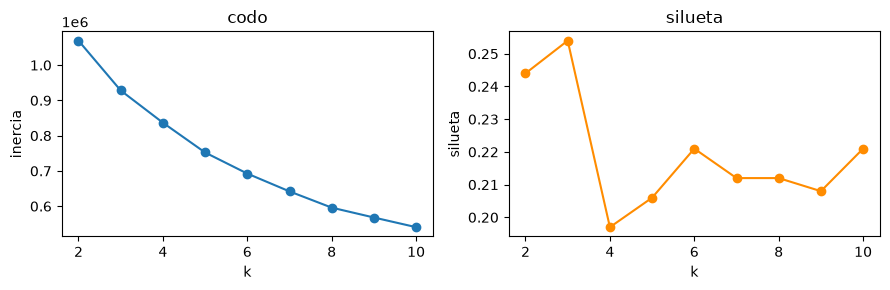

In [5]:
# --- Codo y silueta para elegir k (fold S1) ---
X_fit, X_val = entrenar_fold(X_rango, Y, "S1")

preproceso = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    PCA(n_components=0.95, random_state=SEED),
)
Z = preproceso.fit_transform(X_fit)

filas = []
for k in range(2, 11):
    modelo = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    filas.append({
        "k": k,
        "inercia": modelo.inertia_,
        "silueta": silhouette_score(Z, modelo.labels_, sample_size=min(2000, len(Z)), random_state=SEED),
    })
tabla_k = pd.DataFrame(filas).set_index("k").round(3)
display(tabla_k)

fig, ejes = plt.subplots(1, 2, figsize=(9, 3))
ejes[0].plot(tabla_k.index, tabla_k["inercia"], marker="o")
ejes[0].set_xlabel("k")
ejes[0].set_ylabel("inercia")
ejes[0].set_title("codo")
ejes[1].plot(tabla_k.index, tabla_k["silueta"], marker="o", color="darkorange")
ejes[1].set_xlabel("k")
ejes[1].set_ylabel("silueta")
ejes[1].set_title("silueta")
plt.tight_layout()
plt.show()

## 4. Modelos y metricas Sobre S1

In [6]:
# --- Los tres detectores en el fold S1 ---
X_fit, X_val = entrenar_fold(X_rango, Y, "S1")
X_test = X_rango["S1"].reset_index(drop=True)
y_test = Y["S1"].to_numpy()

filas = []
for nombre in ("kmeans", "birch", "dbscan"):
    detector = Detector(nombre).fit(X_fit, X_val)
    fila = {"modelo": nombre}
    fila.update(metricas(y_test, detector.score(X_test), detector.umbral_))
    filas.append(fila)

tabla_s1 = pd.DataFrame(filas).set_index("modelo")
columnas = ["auc", "recall_5", "recall", "especificidad", "umbral", "flagged"]
display(tabla_s1[columnas].round(3))

,auc,recall_5,recall,especificidad,umbral,flagged
modelo,,,,,,
kmeans,0.584,0.135,0.269,0.841,10.304,387
birch,0.749,0.138,0.219,0.923,6.065,268
dbscan,0.765,0.140,0.239,0.923,6.074,286


### Lectura

El codo y la silueta eligen `k=3` para KMeans en este fold (silueta 0.254). Los tres modelos son scorers, no clusterizadores: los labels no se usan, solo los prototipos.



## 5. Los ocho folds

¿El detector transfiere a un escenario que nunca vio?

Claim 1: transfiere a S0 mejor que el supervisado crudo (especificidad 0.77–0.85 vs 0.39–0.47), pero no parejo. S3 es el caso incómodo: AUC 0.69 y recall 0.

In [7]:
# === 3. Los ocho folds: LOSO ===
filas = []
for modelo in ("kmeans", "birch", "dbscan"):
    filas.append(loso(X_rango, Y, modelo))

tabla_loso = pd.concat(filas, ignore_index=True)

# AUC por escenario reservado
auc = tabla_loso.pivot(index="escenario", columns="modelo", values="auc").reindex(list(X))
display(auc.round(3))

# Especificidad en S0
s0 = tabla_loso[tabla_loso["escenario"] == "S0"][["modelo", "especificidad", "flagged", "n"]]
display(s0.round(3))

# Resumen por modelo
resumen_loso = tabla_loso.groupby("modelo")[["auc", "recall_5", "recall", "especificidad"]].mean()
display(resumen_loso.round(3))


modelo,birch,dbscan,kmeans
escenario,,,
S0,NaN,NaN,NaN
S1,0.749,0.765,0.584
S1-alt,0.336,0.306,0.568
S2,0.889,0.893,0.773
S3,0.558,0.538,0.290
S4,0.928,0.931,0.896
S5,0.904,0.910,0.822
S6,0.757,0.759,0.669


,modelo,especificidad,flagged,n
0,kmeans,0.996,7,1798
8,birch,0.925,134,1798
16,dbscan,0.934,118,1798


,auc,recall_5,recall,especificidad
modelo,,,,
birch,0.731,0.279,0.416,0.881
dbscan,0.729,0.289,0.405,0.877
kmeans,0.657,0.140,0.334,0.904


### Lectura

El ranking por escenario y la brecha entre AUC y recall: el modelo ordena bien en S2/S4/S5/S6, mal en S1alt, y en S3 el umbral no marca nada aunque el AUC sea razonable.

## 6. PCA

Se compara sin PCA, PCA al 95 % y un número fijo de componentes. La evidencia vieja: reducir a 15 columnas físicas sube la especificidad en S0 a 0.98–0.99 pero baja la AUC a 0.62–0.68. El trade-off es real y hay que mostrarlo.

In [8]:
# === 4. Ablación de PCA ===
filas = []
for varianza in (None, 0.95, 5, 10):
    tabla = loso(X_rango, Y, "kmeans", varianza=varianza)
    resumen = tabla.groupby("modelo")[["auc", "recall_5", "recall", "especificidad"]].mean().iloc[0]
    filas.append({
        "PCA": "sin PCA" if varianza is None else str(varianza),
        "AUC": resumen["auc"],
        "recall@5": resumen["recall_5"],
        "recall": resumen["recall"],
        "espec S0": float(tabla.loc[tabla["escenario"] == "S0", "especificidad"].iloc[0]),
    })

comparacion_pca = pd.DataFrame(filas).set_index("PCA")
display(comparacion_pca.round(3))


,AUC,recall@5,recall,espec S0
PCA,,,,
sin PCA,0.637,0.140,0.358,0.933
0.95,0.657,0.140,0.334,0.996
5,0.576,0.110,0.136,0.992
10,0.633,0.084,0.241,0.932


## 7. Comparacion de las transformaciones empleadas en Supervisado

In [9]:
# === Comparación de transformaciones sobre el mejor modelo LOSO (Birch) ===
# Birch es el que mejor le fue en LOSO (AUC 0.731, recall 0.416); se fija el
# modelo y se cambia solo la representación de entrada.
representaciones = {
    "niveles (crudo)": (X, Y),
    "rango móvil 120 s": (X_rango, Y),
    "ventana 20 s": (X_ventana, Y_ventana),
}

filas = []
for nombre, (X_rep, Y_rep) in representaciones.items():
    tabla = loso(X_rep, Y_rep, "birch")
    resumen = tabla.groupby("modelo")[["auc", "recall_5", "recall", "especificidad"]].mean().iloc[0]
    filas.append({
        "representación": nombre,
        "features": X_rep["S1"].shape[1],
        "AUC": resumen["auc"],
        "recall@5": resumen["recall_5"],
        "recall": resumen["recall"],
        "espec S0": float(tabla.loc[tabla["escenario"] == "S0", "especificidad"].iloc[0]),
    })

comparacion_transformaciones = pd.DataFrame(filas).set_index("representación")
display(comparacion_transformaciones.round(3))


,features,AUC,recall@5,recall,espec S0
representación,,,,,
niveles (crudo),132,0.707,0.222,0.379,0.981
rango móvil 120 s,132,0.731,0.279,0.416,0.925
ventana 20 s,2640,0.680,0.206,0.390,0.972


## 8. ¿Que se esta Clusterizando?

¿El detector está midiendo ataques o el paso del tiempo?

Este control es auxiliar y **no forma parte del método no supervisado**. La regresión Ridge se entrena sobre la **posición temporal**, no sobre las etiquetas de ataque: la posición es una variable de confusión, no el objetivo. El detector sigue siendo KMeans/Birch/DBSCAN + PCA y se evalúa con LOSO.

Qué se calcula:

- AUC de usar solo la posición como score.
- R² de predecir la posición desde las features (interpolación).
- Score del detector antes y después de sacar la tendencia temporal.

In [10]:
# === 5. Control: ¿ataque o tiempo? ===
# Un solo DataFrame para el control; el detector usa X_rango.
X_all = pd.concat([X_rango[k] for k in X_rango], ignore_index=True)
y_all = np.concatenate([Y[k].to_numpy() for k in X_rango])
grupo_all = np.concatenate([np.full(len(X_rango[k]), k) for k in X_rango])
pos_all = np.concatenate([np.linspace(0, 1, len(X_rango[k])) for k in X_rango])

# 1) Posición sola y R² de posición desde las features.
# r2_extrapolacion se omite: con bloques contiguos el modelo extrapola y R² explota.
control = control_posicion(X_all, y_all, grupo_all)
display(control[["escenario", "auc_posicion", "r2_posicion"]].round(3))

# 2) Sacar la tendencia temporal y volver a puntuar con el mismo detector.
X_sin_tiempo = residualizar_tiempo(X_all, pos_all, grupo_all)
X_sin_tiempo_dict = {
    k: X_sin_tiempo.loc[grupo_all == k].reset_index(drop=True)
    for k in X_rango
}

tabla_sin_tiempo = loso(X_sin_tiempo_dict, Y, "kmeans")

original = tabla_loso[tabla_loso["modelo"] == "kmeans"].set_index("escenario")
residual = tabla_sin_tiempo.set_index("escenario")
comparacion_tiempo = pd.DataFrame({
    "AUC original": original["auc"],
    "AUC sin tiempo": residual["auc"],
    "delta AUC": residual["auc"] - original["auc"],
    "recall@5 original": original["recall_5"],
    "recall@5 sin tiempo": residual["recall_5"],
    "espec S0 original": original["especificidad"],
    "espec S0 sin tiempo": residual["especificidad"],
})
display(comparacion_tiempo.round(3))


,escenario,auc_posicion,r2_posicion
0,S0,NaN,0.973
1,S1,0.771,0.983
2,S1-alt,0.815,0.986
3,S2,0.755,0.980
4,S3,0.662,0.981
5,S4,0.992,0.974
6,S5,0.987,0.980
7,S6,0.973,0.974


,AUC original,AUC sin tiempo,delta AUC,recall@5 original,recall@5 sin tiempo,espec S0 original,espec S0 sin tiempo
escenario,,,,,,,
S0,NaN,NaN,NaN,NaN,NaN,0.996,0.996
S1,0.584,0.566,-0.017,0.135,0.138,0.841,0.995
S1-alt,0.568,0.376,-0.192,0.000,0.000,0.825,0.865
S2,0.773,0.553,-0.221,0.467,0.000,0.918,0.916
S3,0.290,0.397,0.107,0.000,0.000,0.868,1.000
S4,0.896,0.654,-0.242,0.164,0.134,0.937,0.959
S5,0.822,0.673,-0.149,0.204,0.118,0.908,0.919
S6,0.669,0.350,-0.319,0.010,0.116,0.936,0.991


### Lectura

Si la posición se predice casi perfecto desde las features y el clustering se alinea con el tiempo, el detector tiene que superar ese prior para que su resultado signifique algo.

## 6. Clusterizacion de ataques

¿El clustering identifica familia o escenario, o solo recupera tiempo?

Primero se mira qué representan los grupos cuando se ajustan solo con benigno (regímenes de operación). Después, solo filas de ataque: KMeans con k=3 (familia) y k=8 (escenario); Birch y DBSCAN con su escala; ARI contra familia, escenario y fase, más la tabla de contingencia. Al final, una línea para el conjunto mezclado: cuánto separa ataque de benigno.


In [11]:
# === 6.1 Regímenes de operación: clustering solo con benigno ===
from sklearn.cluster import KMeans

FAMILIA = {
    "S1": "modbus", "S1-alt": "modbus", "S2": "modbus",
    "S3": "arp", "S4": "arp", "S5": "arp",
    "S6": "mqtt",
}

def preparar(X):
    """Imputa, escala y proyecta con PCA; solo para describir, no para predecir."""
    pipe = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        PCA(n_components=0.95, random_state=SEED),
    )
    return pipe.fit_transform(X)

X_benigno = pd.concat([X_rango[k][Y[k] == 0] for k in X_rango], ignore_index=True)
Z_benigno = preparar(X_benigno)
etiquetas_benigno = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit_predict(Z_benigno)

grupo_benigno = np.concatenate([
    np.full(int((Y[k] == 0).sum()), k) for k in X_rango
])
tabla_benigno = pd.crosstab(
    pd.Series(etiquetas_benigno, name="cluster"),
    grupo_benigno,
)
display(tabla_benigno)


col_0,S0,S1,S1-alt,S2,S3,S4,S5,S6
cluster,,,,,,,,
0,119,119,111,119,119,119,119,119
1,685,203,354,17,42,25,0,12
2,474,244,223,297,288,102,62,49
3,9,55,31,31,32,11,27,20
4,511,264,163,401,407,284,251,250


In [12]:
# === 6.2 Tipología de ataques: familia, escenario y fase ===
from sklearn.cluster import Birch, DBSCAN
from sklearn.metrics import adjusted_rand_score, silhouette_score
from src2.unsupervised import escala_vecinos

X_ataque = pd.concat([X_rango[k][Y[k] == 1] for k in X_rango], ignore_index=True)
escenario_ataque = np.concatenate([
    np.full(int((Y[k] == 1).sum()), k) for k in X_rango
])
familia_ataque = np.array([FAMILIA[s] for s in escenario_ataque])

def grupo_fase(p):
    p = str(p).lower()
    if "recon" in p:
        return "recon"
    if "phase_1" in p:
        return "phase_1"
    if "phase_2" in p:
        return "phase_2"
    if "price" in p:
        return "mqtt_price"
    if "attack_mqtt" in p or "impact" in p or "industroyer_active" in p:
        return "impact"
    return "otro"

fase_ataque = np.array([
    grupo_fase(p)
    for k in X_rango
    for p in brutos[k].loc[Y[k] == 1, "attack_phase"]
])

Z_ataque = preparar(X_ataque)

def etiquetas_modelo(Z, modelo, k=None):
    if modelo == "kmeans":
        return KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Z)
    escala = escala_vecinos(Z)
    if modelo == "birch":
        return Birch(threshold=escala, n_clusters=None).fit_predict(Z)
    if modelo == "dbscan":
        return DBSCAN(eps=escala, min_samples=5).fit_predict(Z)
    raise ValueError(f"modelo desconocido: {modelo}")

filas = []
for modelo, k in (("kmeans", 3), ("kmeans", 8), ("birch", None), ("dbscan", None)):
    etiquetas = etiquetas_modelo(Z_ataque, modelo, k)
    filas.append({
        "modelo": modelo,
        "k": k if k is not None else len(np.unique(etiquetas)),
        "ARI familia": adjusted_rand_score(familia_ataque, etiquetas),
        "ARI escenario": adjusted_rand_score(escenario_ataque, etiquetas),
        "ARI fase": adjusted_rand_score(fase_ataque, etiquetas),
        "silhouette": silhouette_score(
            Z_ataque, etiquetas,
            sample_size=min(2000, len(Z_ataque)),
            random_state=SEED,
        ) if len(np.unique(etiquetas)) > 1 else np.nan,
    })

tabla_ataque = pd.DataFrame(filas).set_index(["modelo", "k"])
display(tabla_ataque.round(3))

# Contingencia del k=3 contra familia
etiquetas_k3 = etiquetas_modelo(Z_ataque, "kmeans", 3)
display(pd.crosstab(
    pd.Series(etiquetas_k3, name="cluster"),
    familia_ataque,
))


ARI familia  ARI escenario  ARI fase  silhouette
modelo k                                                    
kmeans 3          0.292          0.205     0.103       0.150
       8          0.100          0.164     0.065       0.199
birch  440        0.012          0.040     0.010       0.691
dbscan 479        0.008          0.029     0.008       0.656

col_0,arp,modbus,mqtt
cluster,,,
0,960,949,711
1,2364,66,283
2,186,1711,356


In [16]:
# === 6.3 Todo mezclado: ¿separa ataque de benigno? ===
X_todo = pd.concat([X_rango[k] for k in X_rango], ignore_index=True)
y_todo = np.concatenate([Y[k].to_numpy() for k in X_rango])
grupo_todo = np.concatenate([np.full(len(X_rango[k]), k) for k in X_rango])
Z_todo = preparar(X_todo)

etiquetas_8 = KMeans(n_clusters=8, n_init=10, random_state=SEED).fit_predict(Z_todo)
etiquetas_2 = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit_predict(Z_todo)

resumen_mezclado = pd.DataFrame([
    {"comparación": "escenario (k=8)", "ARI": adjusted_rand_score(grupo_todo, etiquetas_8)},
    {"comparación": "ataque/benigno (k=2)", "ARI": adjusted_rand_score(y_todo, etiquetas_2)},
])
display(resumen_mezclado.round(3))


,comparación,ARI
0,escenario (k=8),0.083
1,ataque/benigno (k=2),0.160


### Lectura

**Benigno.** Los cinco grupos mezclan escenarios: son regímenes de operación, no escenarios.

**Ataques.** El mejor ARI de familia es 0.292 (KMeans k=3); k=8 da 0.100; Birch y DBSCAN quedan en 0.012 y 0.008. El ARI de fase no pasa de 0.103. La contingencia muestra un Modbus/ARP parcialmente separado y MQTT mezclado.

**Todo mezclado.** ARI escenario 0.083 y ARI ataque/benigno 0.160: el clustering no separa ataque de benigno ni recupera la identidad del ataque.

Conclusión: recupera tiempo y régimen operativo, no familia.


### Lectura

Se demuestra el circuito —archivo, transformación, puntaje, umbral, alerta—, no el rendimiento.

## 7. Conclusiones

**Qué establecimos.**

1. **El detector benign-only funciona a medias.** Con rango móvil, Birch y DBSCAN alcanzan AUC ~0.73 y KMeans 0.657. S2, S4, S5 y S6 se ordenan bien (0.77–0.93); S1alt y S3 fallan (0.29–0.56). La especificidad en S0 es alta en LOSO (0.925–0.996), pero a costa de no detectar en esos folds.
2. **El cuello es el umbral.** En LOSO la AUC se sostiene (media 0.66–0.73) pero el recall se derrumba en varios folds: 0 en S3 (KMeans) y recall@5 0 en S1-alt (Birch y DBSCAN). La fracción marcada oscila entre 0.004 y 0.602: el p95 del benigno de entrenamiento no representa al resto de los escenarios. El modelo ordena; el corte no transfiere.
3. **El tiempo domina.** La posición sola predice ataques con AUC 0.662–0.992 según el escenario, y la posición se reconstruye desde las features con R² 0.974–0.986. En casi todos los folds, la posición sola supera a KMeans. El clustering de ataques no recupera familia (ARI ≤ 0.292) ni fase (≤ 0.103); el conjunto mezclado tampoco separa ataque de benigno (ARI 0.160).
4. **La tipología no aparece.** Los grupos benignos son regímenes operativos, no escenarios; los grupos de ataque se mezclan por familia y escenario.

**La tesis.** Un detector entrenado solo con benigno transfiere a S0 mejor que el supervisado crudo, pero no parejo; el límite no es el modelo sino el umbral, que no transfiere entre escenarios; y el clustering recupera tiempo y régimen operativo, no identidad de ataque.

**Límites.** S0 es un solo escenario limpio; los ataques están anclados en una franja temporal. La ablación de PCA y la producción quedan pendientes de cerrar.
